In [6]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="niDWrRGgqWzpINmIma3q")
project = rf.workspace("robert-demo-qvail").project("pokedex")
dataset = project.version(1).download("folder")

loading Roboflow workspace...
loading Roboflow project...


In [7]:
!pip install ultralytics
import os
from ultralytics import YOLO

# Ver qué carpetas hay en el directorio actual para encontrar la ruta exacta
print("Carpetas disponibles:", os.listdir('.'))

# Cargar el modelo preentrenado de clasificación
model = YOLO('yolov8n-cls.pt')

# Entrenar apuntando a la ruta local (asegúrate de poner el nombre exacto que te imprima arriba, por ejemplo './Pokedex-1')
results = model.train(
    data='Pokedex-1',  # Cambia esto si el nombre de la carpeta es diferente
    epochs=10,
    imgsz=224,
    batch=16
)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Carpetas disponibles: ['.config', 'Pokedex-1', 'Imagen1.png', 'sample_data']
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=T

In [8]:
pip install ultralytics


image 1/1 /content/Imagen1.png: 224x224 Articuno 0.05, Golduck 0.03, Seadra 0.03, Vaporeon 0.02, Lapras 0.02, 23.6ms
Speed: 5.9ms preprocess, 23.6ms inference, 0.2ms postprocess per image at shape (1, 3, 224, 224)


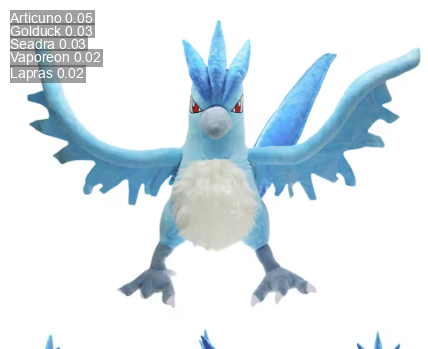

Clase predicha (índice): 6
Confianza: 4.94%
Nombre del Pokémon: Articuno


In [20]:
from ultralytics import YOLO
import os

# 1. Cargar el modelo entrenado apuntando a la ruta correcta
# Si tienes múltiples entrenamientos, la carpeta podría llamarse 'train2', 'train3', etc.
weights_path = 'runs/classify/train/weights/best.pt'

if os.path.exists(weights_path):
    model = YOLO(weights_path)
else:
    # Buscar alternativa si se entrenó en otra carpeta
    print("No se encontró en 'train', intentando buscar en carpetas de 'runs/'...")
    model = YOLO('best.pt')  # Reintento por defecto

# 2. Probar con una de tus imágenes de prueba
results = model('Imagen1.png')

# 3. Mostrar el resultado de la clasificación en pantalla
results[0].show()

# Opcional: ver los detalles de la predicción (clase y nivel de confianza)
probs = results[0].probs
print(f"Clase predicha (índice): {probs.top1}")
print(f"Confianza: {probs.top1conf.item() * 100:.2f}%")
print(f"Nombre del Pokémon: {results[0].names[probs.top1]}")


image 1/1 /content/imagen2.png: 224x224 Mew 0.10, Wigglytuff 0.04, Seel 0.02, Jigglypuff 0.02, Clefable 0.02, 12.8ms
Speed: 18.3ms preprocess, 12.8ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)


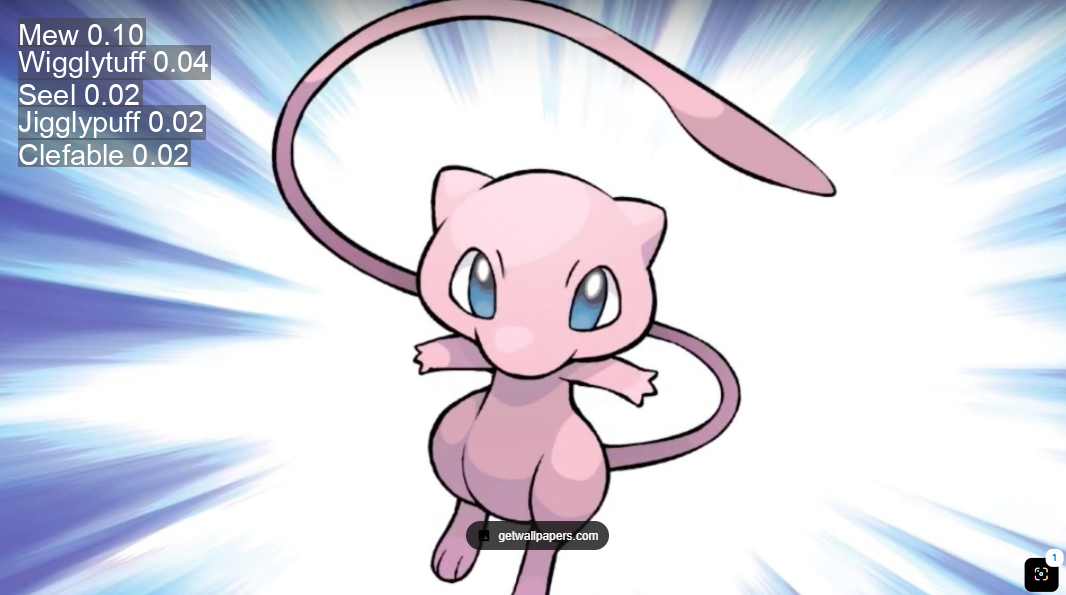

Clase predicha (índice): 82
Confianza: 9.53%
Nombre del Pokémon: Mew


In [18]:
from ultralytics import YOLO

# 1. Cargar el modelo entrenado
model = YOLO('best.pt')

# 2. Probar con una de tus imágenes de prueba
results = model('imagen2.png')

# 3. Mostrar el resultado de la clasificación en pantalla
results[0].show()

# Opcional: ver los detalles de la predicción (clase y nivel de confianza)
probs = results[0].probs
print(f"Clase predicha (índice): {probs.top1}")
print(f"Confianza: {probs.top1conf.item() * 100:.2f}%")
print(f"Nombre del Pokémon: {results[0].names[probs.top1]}")

In [19]:
from roboflow import Roboflow

rf = Roboflow(api_key="niDWrRGgqWzpINmIma3q")
project = rf.workspace("gaspar-lammel").project("pokedex")
version = project.version(1)
dataset = version.download("folder")

loading Roboflow workspace...
loading Roboflow project...


In [ ]:
from ultralytics import YOLO

# Cargar un modelo base de clasificación preentrenado (ej. yolov8n-cls.pt o yolov8s-cls.pt)
model = YOLO('yolov8n-cls.pt')

# Entrenar con el nuevo dataset por más épocas y ajustando el tamaño de imagen si es necesario
model.train(
    data=dataset.location,
    epochs=50,          # Puedes subir a 50 o más con early stopping
    imgsz=224,          # Resolución estándar para clasificación
    batch=16,           # Ajusta según la VRAM de tu GPU
    device='cpu'            # Usar GPU si está disponible
)


image 1/1 /content/imagen2.png: 224x224 Mew 0.10, Wigglytuff 0.04, Seel 0.02, Jigglypuff 0.02, Clefable 0.02, 16.3ms
Speed: 12.9ms preprocess, 16.3ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)


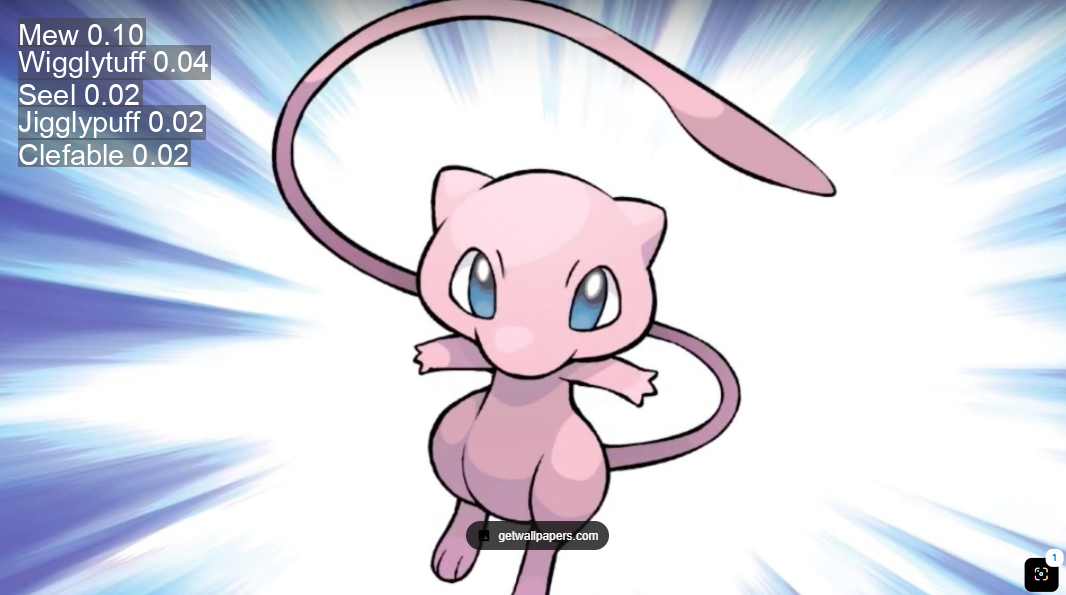

Clase predicha (índice): 82
Confianza: 9.53%
Nombre del Pokémon: Mew


In [21]:
from ultralytics import YOLO

# 1. Cargar el modelo entrenado
model = YOLO('best.pt')

# 2. Probar con una de tus imágenes de prueba
results = model('imagen2.png')

# 3. Mostrar el resultado de la clasificación en pantalla
results[0].show()

# Opcional: ver los detalles de la predicción (clase y nivel de confianza)
probs = results[0].probs
print(f"Clase predicha (índice): {probs.top1}")
print(f"Confianza: {probs.top1conf.item() * 100:.2f}%")
print(f"Nombre del Pokémon: {results[0].names[probs.top1]}")